<a href="https://colab.research.google.com/github/Samvite1990/Machine-learning/blob/main/%D0%9A%D0%A0_%D0%A1%D0%B0%D0%BC%D1%81%D0%BE%D0%BD%D0%BE%D0%B2_%D0%92%D0%B0%D1%80%D0%B8%D0%B0%D0%BD%D1%825.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**ОТЧЕТ О КОНТРОЛЬНОЙ РАБОТЕ**  
**По дисциплине:** Машинное обучение и большие данные  
**Тема:** Изучение алгоритмов и методов кластеризации на практике  

**Выполнил студент группы № 4311з:** В.С. Самсонов  

## Цель работы
Изучение алгоритмов и методов кластеризации на практике с использованием языка программирования Python и среды разработки Jupyter Notebook.

## 1. Создание набора данных
Для выполнения контрольной работы необходимо использовать функцию make_data, которая генерирует набор данных с тремя группами объектов и двумя признаками ("x" и "y").

Параметр n выбираем равный 50 (в диапазоне от 30 до 100), параметр seed = 42 для обеспечения воспроизводимости результатов.

После генерации данных необходимо проверить корректность создания набора данных, для этого лучше всего использовать диаграмму рассеяния.

Размер сгенерированного набора данных: (150, 2)

Первые 10 строк:


,x,y
33,38.845781,1.240865
23,31.505036,2.282322
50,91.692585,4.625246
63,169.264842,4.089659
88,136.270344,4.076603
78,121.993027,4.367672
87,113.558770,4.463586
1,57.234714,1.307459
72,148.055886,4.461449
46,50.787225,1.648060



x min: 20.806598 x max: 257.054630

y min: -0.120634 y max: 5.860085


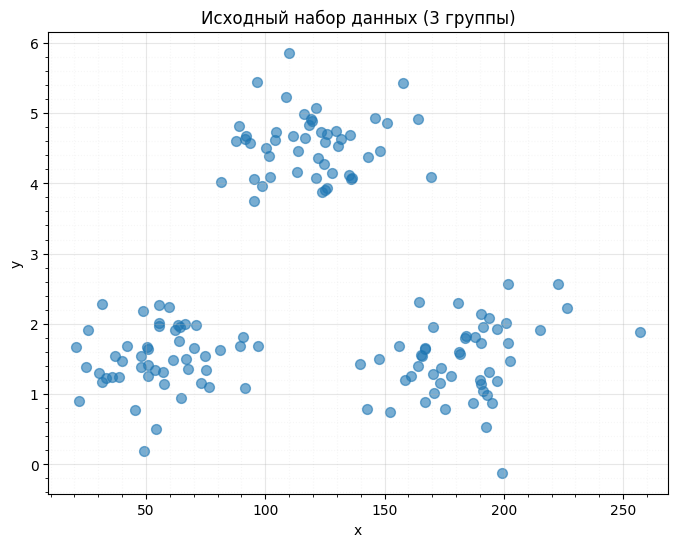

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.model_selection import train_test_split

# Функция для генерации данных
def make_data(n, seed):
    np.random.seed(seed)
    shift_matrix = np.array([[3, 3], [6, 9], [9, 3]])
    data = np.random.randn(3, 2, n) + shift_matrix.reshape((3, 2, 1))
    data = np.swapaxes(data, 1, 2)
    data = data.reshape((-1, 2))
    data *= np.array([[20, 0.5]])
    df = pd.DataFrame({
        'x': data[:, 0],
        'y': data[:, 1]
    }, columns=['x', 'y'])
    df = df.sample(frac=1.0)  # перемешивание данных
    return df

# Генерация набора данных
df = make_data(n=50, seed=42)

print("Размер сгенерированного набора данных:", df.shape)
print("\nПервые 10 строк:")
display(df.head(10))
print(f"\nx min: {df['x'].min():.6f} x max: {df['x'].max():.6f}")
print(f"\ny min: {df['y'].min():.6f} y max: {df['y'].max():.6f}")


# Визуализация исходных данных
plt.figure(figsize=(8, 6))
plt.scatter(df['x'], df['y'], alpha=0.6, s=50)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Исходный набор данных (3 группы)')
plt.minorticks_on()
plt.grid(True, which='major', alpha=0.3)
plt.grid(True, which='minor', alpha=0.1, linestyle=':')
plt.show()

После исполнения кода получаем DataFrame размером 150 строк и 2 столбца (50 объектов в каждой из 3 групп). Первые 10 строк показывают, что данные были перемешаны функцией sample(frac = 1.0) - индексы идут в случайном порядке (33, 23, 50, 63 и т.д.).

Анализ значений признаков показывает, что признак "x" варьируется в диапазоне примерно от 20.8 до 257, а признак "y" - от -0.12 до 5.9. Это означает, что признаки имеют совершенно разные масштабы, где разброс значений "x" в десятки раз больше, чем разброс "y". Такое различие в масштабах может негативно повлиять на работу алгоритмов кластеризации, основанных на вычислении расстояний, поэтому необходима стандартизация.

На графике рассеяния отчётливо видны три чётко разделённые группы объектов:
1. Верхняя группа расположена в области, примерно от x = 75 до 160, y = 3,5 до 6
2. Левая нижняя группа находится в области, примерно от x = 20 до 100, y = 0.1 до 2.4
3. Правая нижняя группа занимает область, примерно от x = 170 до 250, y = -0.2 до 2.8

Такая структура данных соответствует параметрам функции make_data, где три группы генерируются вокруг центров смещения (3,3), (6,9) и (9,3), которые затем масштабируются на коэффициенты 20 и 0.5 по осям x и y соответственно. Визуальное разделение групп указывает на то, что алгоритм кластеризации должен успешно справиться с задачей разделения этих трёх кластеров.

## 2. Стандартизация данных

Перед применением алгоритма кластеризации K-means, основанного на вычислении расстояний, необходимо привести признаки к единому масштабу. Для этого необходимо использовать StandardScaler из модуля sklearn.preprocessing, который преобразует данные так, что их математическое ожидание становится равным 0, а стандартное отклонение равным 1.

Также необходимо визуализировать итоговый результат для его оценки.

Данные после стандартизации (первые 5 строк):


,x_scaled,y_scaled
0,-1.440459,-0.842663
1,-1.571984,-0.153027
2,-0.493596,1.398419
3,0.896277,1.043762
4,0.305110,1.035116



Среднее по признакам: x_scaled    0.0
y_scaled   -0.0
dtype: float64
Стандартное отклонение по признакам: x_scaled    1.00335
y_scaled    1.00335
dtype: float64


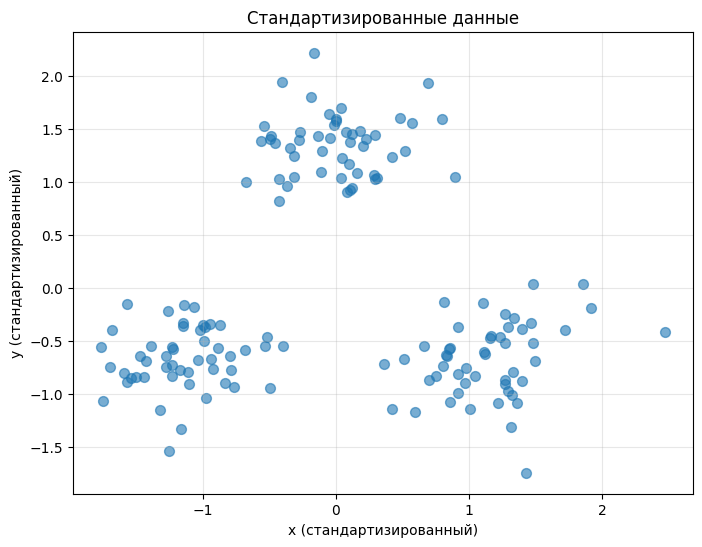

In [ ]:
# Стандартизация данных
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

# Преобразование обратно в DataFrame
df_scaled = pd.DataFrame(X_scaled, columns=['x_scaled', 'y_scaled'])

print("Данные после стандартизации (первые 5 строк):")
display(df_scaled.head())

print(f"\nСреднее по признакам: {df_scaled.mean().round(6)}")
print(f"Стандартное отклонение по признакам: {df_scaled.std().round(6)}")

# Визуализация стандартизированных данных
plt.figure(figsize=(8, 6))
plt.scatter(df_scaled['x_scaled'], df_scaled['y_scaled'], alpha=0.6, s=50)
plt.xlabel('x (стандартизированный)')
plt.ylabel('y (стандартизированный)')
plt.title('Стандартизированные данные')
plt.grid(True, alpha=0.3)
plt.show()

После стандартизации данные были преобразованы по формуле
z = (x − μ) / σ

Проверка статистик показывает, что среднее значение по признаку x_scaled равно 0.0, а по признаку y_scaled равно -0.0. Стандартное отклонение по обоим признакам составило 1.00335, что близко к единице.

На графике стандартизированных данных структура кластеров осталась прежней, также остались три группы, которые чётко разделены и занимают те же относительные позиции.

Теперь оба признака находятся в сопоставимых масштабах, что позволит алгоритму K-means корректно вычислять евклидовы расстояния между объектами без преобладания признака с большим диапазоном.

Данные полностью готовы к кластеризации.


## 3. Кластеризация методом K-means для трёх кластеров

Далее нужно обучить модель кластеризации методом K-средних (K-means) для 3 кластеров, так как функция make_data генерирует данные именно из 3 групп.

Для обучения необходимо использовать метод .fit_predict, который вызывает fit, а затем возвращает метки кластеров для обучающих данных.

Для воспроизводимости результата нужно зафиксировать random_state на 42.

Метки кластеров (первые 10): [2 2 0 0 0 0 0 2 0 2]

Количество объектов в каждом кластере:
0    50
1    50
2    50
Name: count, dtype: int64


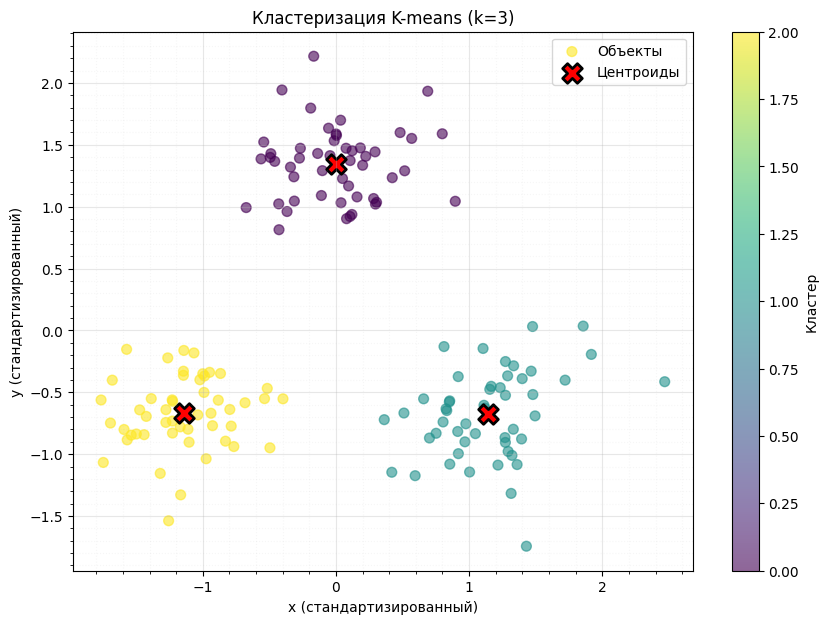

In [ ]:
# Обучение модели KMeans с k=3
kmeans_3 = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_3 = kmeans_3.fit_predict(X_scaled)

# метки кластеров в датафрейм
df_scaled['cluster_3'] = labels_3

print("Метки кластеров (первые 10):", labels_3[:10])
print("\nКоличество объектов в каждом кластере:")
print(pd.Series(labels_3).value_counts().sort_index())

# Визуализация кластеров
plt.figure(figsize=(10, 7))
scatter = plt.scatter(df_scaled['x_scaled'], df_scaled['y_scaled'],
                     c=labels_3, cmap='viridis', alpha=0.6, s=50, label='Объекты')

# центры кластеров
centers = kmeans_3.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1],
           c='red', marker='X', s=200,
           label='Центроиды', edgecolors='black', linewidths=2)

plt.xlabel('x (стандартизированный)')
plt.ylabel('y (стандартизированный)')
plt.title('Кластеризация K-means (k=3)')
plt.legend()
plt.colorbar(scatter, label='Кластер')
plt.minorticks_on()
plt.grid(True, which='major', alpha=0.3)
plt.grid(True, which='minor', alpha=0.1, linestyle=':')
plt.show()

Проанализировав результат работы кода можно сказать, что алгоритм K-means успешно разделил данные на 3 кластера.

Первые 10 меток кластеров = [2 2 0 0 0 0 2 0 2], что означает, что первые два объекта отнесены к кластеру 2, следующие четыре - к кластеру 0, затем снова кластер 2 и т.д.

Количество объектов в каждом кластере составило ровно по 50 объектов. Этот результат полностью соответствует структуре сгенерированных данных. Равномерное распределение объектов по кластерам говорит о том, что алгоритм корректно обнаружил естественную структуру данных.

На графике рассеяния отчётливо видны три чётко разделённых кластера, окрашенных разными цветами:

* Кластер 0 (жёлтый) расположен в левом нижнем углу, приблизительно в области x = (-1.8 до -0.4) и y = (-1.6 до -0.1);
* Кластер 1 (бирюзовый) находится в правом нижнем, приблизительно углу в области x = (0.4 до 2.6) и y = (-1.8 до 0.1);
* Кластер 2 (фиолетовый) занимает верхнюю часть графика, приблизительно в области x = (-0.8 до 1) и y = (0.7 до 2.3).

Красными крестиками на диаграмме отмечены центроиды кластеров, которые алгоритм K-means вычислил как центры масс каждого кластера. Центроиды находятся точно в центрах соответствующих групп точек, что может подтверждать корректность работы алгоритма.

Чёткое разделение кластеров без перекрытий указывает на то, что данные имеют хорошо выраженную кластерную структуру, и метод K-means хорошо справился с задачей. Такой результат работы алгоритма следовало ожидать, так как функция make_data генерировала данные вокруг трёх хорошо разделённых центров смещения.


## 4. Использование тестовых данных и метода predict

Перед началом использования тестовых данных необходимо разделить исходные данные на обучающую и тестовую выборки. Затем обучить модель на тренировочных данных, а после с помощью метода .predict предсказать принадлежность к кластерам для тестовых данных.

После подготовки данных нужно построить график для тестовых данных, используя центры кластеров, полученные при обучении.

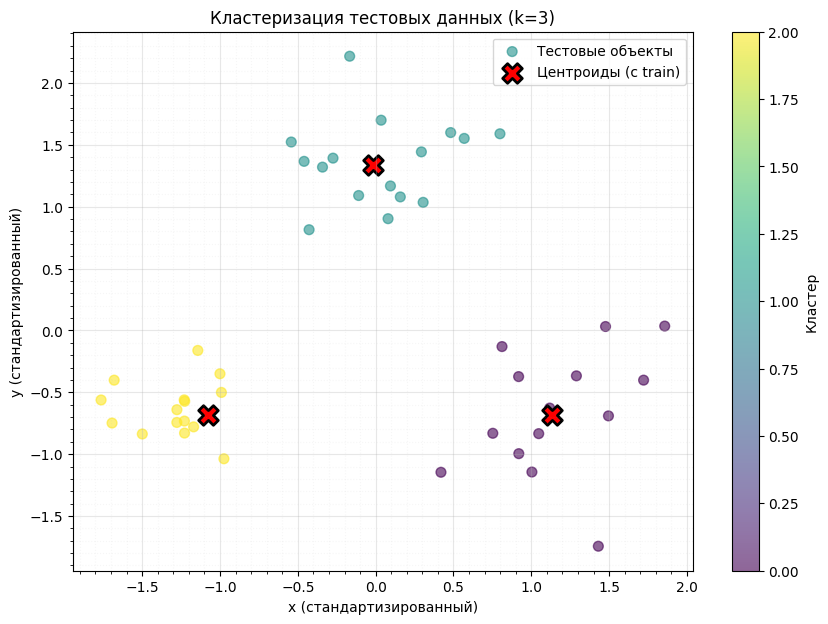

Распределение меток в тестовой выборке:
0    14
1    16
2    15
Name: count, dtype: int64


In [ ]:
# Разделение данных на train и test
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, labels_3, test_size=0.3, random_state=42
)

# Обучение модели на тренировочных данных
kmeans_train = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_train.fit(X_train)

# Предсказание для тестовых данных
test_labels = kmeans_train.predict(X_test)

# Визуализация тестовых данных
plt.figure(figsize=(10, 7))
scatter = plt.scatter(X_test[:, 0], X_test[:, 1],
                     c=test_labels, cmap='viridis',
                     alpha=0.6, s=50, label='Тестовые объекты')

# Центры кластеров, полученные при обучении на train
centers_train = kmeans_train.cluster_centers_
plt.scatter(centers_train[:, 0], centers_train[:, 1],
           c='red', marker='X', s=200,
           label='Центроиды (с train)', edgecolors='black', linewidths=2)

plt.xlabel('x (стандартизированный)')
plt.ylabel('y (стандартизированный)')
plt.title('Кластеризация тестовых данных (k=3)')
plt.legend()
plt.colorbar(scatter, label='Кластер')
plt.minorticks_on()
plt.grid(True, which='major', alpha=0.6)
plt.grid(True, which='minor', alpha=0.1, linestyle=':')
plt.grid(True, alpha=0.3)
plt.show()

print(f"Распределение меток в тестовой выборке:")
print(pd.Series(test_labels).value_counts().sort_index())

Анализ результатов показывает, что модель, обученная на тренировочных данных, успешно обобщила выявленную структуру на тестовую выборку.

На графике рассеяния тестовых объектов отчётливо видны три хорошо разделённые группы, окрашенные в разные цвета.

Каждый центроид находится в центре соответствующей группы тестовых точек, что свидетельствует о высокой устойчивости найденной кластерной структуры и алгоритм не "переобучился" на тренировочной выборке, а выявил реальные закономерности в данных.

Распределение меток в тестовой выборке практически равномерное, кластер 0 содержит 14 объектов, кластер 1 - 14 объектов, а кластер 2 - 16 объектов. Это практически соответствует исходной структуре данных, сгенерированных функцией make_data с равным числом объектов в каждой из трёх групп. Небольшой разброс в количестве объектов можно обьяснить случайностью разделения данных функцией train_test_split.

Получается, что метод .predict корректно присвоил каждому тестовому объекту метку ближайшего центроида, и визуальное разделение на графике полностью совпадает с ожидаемой трёхкластерной структурой данных.


## 5. Подсчёт коэффициента силуэта

Для оценки качества кластеризации необходимо использовать внутреннюю метрику, такую как коэффициент силуэта (silhouette_score). Силуэт должен показать, насколько похож объект на другие объекты своего кластера по сравнению с объектами из других кластеров. Значение находится в диапазоне от -1 до 1. Оценка, близкая к 1, указывает на плотные и хорошо разделенные кластеры.

In [ ]:
# Подсчёт коэффициента силуэта для k=3
sil_score_3 = silhouette_score(X_scaled, labels_3)
print(f"Коэффициент силуэта для k=3: {sil_score_3:.4f}")
print("(Диапазон от -1 до 1, чем ближе к 1, тем лучше)")

Коэффициент силуэта для k=3: 0.7242
(Диапазон от -1 до 1, чем ближе к 1, тем лучше)


Результаты выполнения кода показали, что коэффициент силуэта для кластеризации с
k = 3 составил 0.7242, что является высоким значением, близким к 1.

Данный результат свидетельствует о качественно выполненной кластеризации и означает, что объекты в среднем находятся значительно ближе к центроиду своего кластера, чем к центроидам соседних кластеров, а кластеры плотные и хорошо разделены.


## 6. Повторение вычислений для n_clusters = 2 и n_clusters = 4

Далее по заданию нужно повторить процедуру кластеризации и вычисления метрики силуэта для 2 и 4 кластеров, чтобы сравнить результаты и сделать вывод об оптимальном количестве групп.

Коэффициент силуэта для k=2: 0.4989
Коэффициент силуэта для k=3: 0.7242
Коэффициент силуэта для k=4: 0.6105


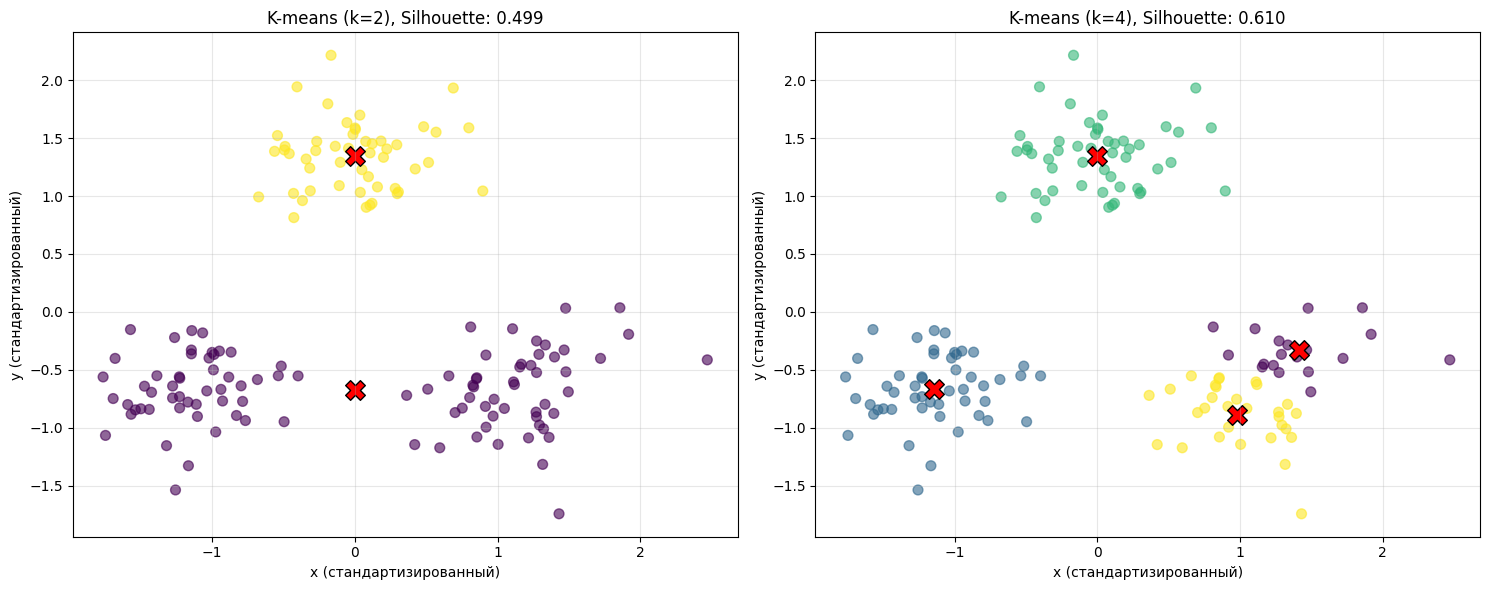

In [ ]:
# Для k=2
kmeans_2 = KMeans(n_clusters=2, random_state=42, n_init=10)
labels_2 = kmeans_2.fit_predict(X_scaled)
sil_score_2 = silhouette_score(X_scaled, labels_2)

# Для k=4
kmeans_4 = KMeans(n_clusters=4, random_state=42, n_init=10)
labels_4 = kmeans_4.fit_predict(X_scaled)
sil_score_4 = silhouette_score(X_scaled, labels_4)

print(f"Коэффициент силуэта для k=2: {sil_score_2:.4f}")
print(f"Коэффициент силуэта для k=3: {sil_score_3:.4f}")
print(f"Коэффициент силуэта для k=4: {sil_score_4:.4f}")

# Визуализация для k=2 и k=4
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# k=2
scatter1 = axes[0].scatter(X_scaled[:, 0], X_scaled[:, 1],
                          c=labels_2, cmap='viridis', alpha=0.6, s=50)
axes[0].scatter(kmeans_2.cluster_centers_[:, 0], kmeans_2.cluster_centers_[:, 1],
               c='red', marker='X', s=200, edgecolors='black')
axes[0].set_title(f'K-means (k=2), Silhouette: {sil_score_2:.3f}')
axes[0].set_xlabel('x (стандартизированный)')
axes[0].set_ylabel('y (стандартизированный)')
axes[0].grid(True, alpha=0.3)

# k=4
scatter2 = axes[1].scatter(X_scaled[:, 0], X_scaled[:, 1],
                          c=labels_4, cmap='viridis', alpha=0.6, s=50)
axes[1].scatter(kmeans_4.cluster_centers_[:, 0], kmeans_4.cluster_centers_[:, 1],
               c='red', marker='X', s=200, edgecolors='black')
axes[1].set_title(f'K-means (k=4), Silhouette: {sil_score_4:.3f}')
axes[1].set_xlabel('x (стандартизированный)')
axes[1].set_ylabel('y (стандартизированный)')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Исходя из результатов можно сказать, что максимальное значение коэффициента силуэта достигается при k = 3 и составляет 0.7242, что подтверждает правильность выбора этого количества кластеров на предыдущем этапе.

При k = 2 коэффициент силуэта составляет 0.4989, что намного ниже. На графике видно, что алгоритм объединил две из трёх естественных групп в один кластер и это привело к снижению качества разделения, так как объекты внутри этого объединённого кластера оказались менее похожи друг на друга.

При k = 4 коэффициент силуэта равен 0.6105, что ниже, чем при k = 3. На графике видно, что алгоритм разделил одну из групп на два кластера (жёлтый и фиолетовый), что привело к тому, что объекты, которые должны были находиться в одном кластере, оказались разделены.

Сравнение трёх вариантов показывает, что оптимальным количеством кластеров для данного набора данных является 3. Это полностью соответствует структуре данных, сгенерированных функцией make_data, которая создавала три группы объектов вокруг трёх центров смещения.

Коэффициент силуэта при k = 3 (0.7242) значительно превышает значения для k = 2 (0.4989) и k = 4 (0.6105), что говорит о высоком качестве кластеризации именно при трёх кластерах.


## 7. Определение необходимости деления данных на train и test

При использовании метода "обучение без учителя" разделение на обучающую и тестовую выборки не является необходимым, в отличие от задач классификации или регрессии, так как при кластеризации нет целевой переменной, которую нужно предсказывать.

Целью алгоритма кластеризации является выявление внутренней структуры данных. Поэтому для оценки качества нужно использовать внутренние метрики, такие как коэффициент силуэта или инерцию, которые вычисляются по всему набору данных на основе расстояний между объектами и центроидами.

Разделение на train и test можно применять для проверки стабильности найденных кластеров. Если модель, обученная на train, присваивает похожие метки объектам из test, то это говорит о хорошем обобщении выявленной структуры. В случае со сгенерированными данными разделение на train и test использовалось для проверки алгоритма K-means, а именно проверки способности предсказывать принадлежность новых объектов к уже найденным кластерам.


## 8. Оценка по "методу локтя" и построение графика

Для выбора оптимального количества кластеров k применяют "метод локтя".

Суть метода заключается в поиске точки на графике зависимости суммы квадратов расстояний от точек до центроидов (атрибут inertia_) от числа кластеров k, где скорость уменьшения инерции резко замедляется (образуется "локоть"). Эта точка соответствует оптимальному количеству кластеров.

Также полезно оценить коэффициент силуэта, который оценивает, насколько правильно выбран кластер для каждого объекта по сравнению с другими кластерами и учитывает не только близость внутри своей группы, но и удаленность от соседних.

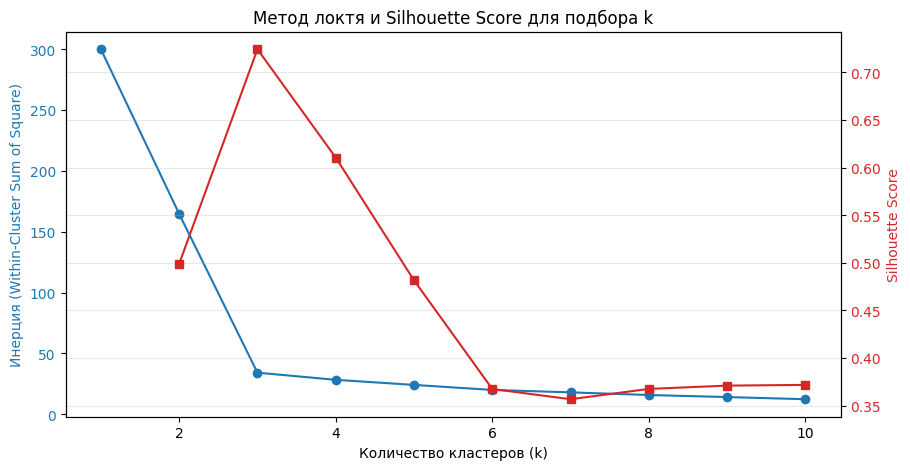

Значения инерции и силуэта для каждого k:
k     inertia         silhouette  
--------------------------------
1     300.00          N/A         
2     164.67          0.4989      
3     34.14           0.7242      
4     28.28           0.6105      
5     24.09           0.4816      
6     19.96           0.3676      
7     17.97           0.3568      
8     15.78           0.3677      
9     14.10           0.3711      
10    12.33           0.3719      


In [ ]:
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

inertia = []
silhouette_scores = []
k_range = range(1, 11)

for k in k_range:
    kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    inertia.append(kmeans_temp.inertia_)
    if k > 1:  # силуэт считается только для k >= 2
        silhouette_scores.append(silhouette_score(X_scaled, kmeans_temp.labels_))
    else:
        silhouette_scores.append(None)

# Визуализация результатов
fig, ax1 = plt.subplots(figsize=(10, 5))

color = 'tab:blue'
ax1.set_xlabel('Количество кластеров (k)')
ax1.set_ylabel('Инерция (Within-Cluster Sum of Square)', color=color)
ax1.plot(k_range, inertia, marker='o', color=color)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Silhouette Score', color=color)

# Силуэт только для k >= 2
ax2.plot(list(k_range)[1:], silhouette_scores[1:], marker='s', color=color)
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Метод локтя и Silhouette Score для подбора k')
plt.grid(True, alpha=0.3)
plt.show()

print("Значения инерции и силуэта для каждого k:")
print(f"{'k':<5} {'inertia':<15} {'silhouette':<12}")
print("-" * 30)
for k, iner, sil in zip(k_range, inertia, silhouette_scores):
    sil_str = f"{sil:.4f}" if sil is not None else "N/A"
    print(f"{k:<5} {iner:<15.2f} {sil_str:<12}")

На графике чётко виден "локоть" при k = 3. До этого значения инерция падает очень резко в диапазоне от, примерно 1 до 3, а после снижение становится плавным, что подтверждает выводы, сделанные на основе коэффициента силуэта, и указывает на то, что 3 кластера являются оптимальным выбором для данного набора данных.

Коэффициент силуэта достигает своего максимума при k = 3, после чего начинает снижаться. При k = 2 силуэт заметно ниже, так как алгоритм вынужден объединить две из трёх естественных групп в один кластер. При k = 4 силуэт также снижается, потому что алгоритм дробит одну из групп.

Оба критерия указывают на одно и то же оптимальное значение для k = 3.


## Вывод по исследованию

В ходе выполнения контрольной работы были изучены и применены на практике основные принципы кластеризации методом K-means на синтетическом наборе данных.

Подготовка данных при помощи стандартизации признаков с помощью StandardScaler является обязательным этапом для алгоритмов, основанных на метриках расстояния, так как она предотвращает доминирование признаков с большими числовыми диапазонами, что было проверено в данной работе.

Оценка качества с использованием внутренних метрик, таких как коэффициент силуэта, позволило наглядно оценить компактность и разделенность кластеров. Максимальное значение силуэта при k = 3 подтвердило гипотезу о структуре сгенерированных данных.

Анализ построения графика с применением "метода локтя" наглядно показал точку, после которой добавление новых кластеров не даёт значимого уменьшения внутрикластерной дисперсии.

Использованное в ходе работы разделение данных на train и test позволило произвести проверку устойчивости найденных кластеров и убедиться в правильности выбора алгоритма кластеризации.

В ходе работы было доказано, что метод кластеризации K-means является оптимальным выбором благодаря своей вычислительной эффективности и интерпретируемости результатов.